<center><image src="https://drive.google.com/uc?id=1n3G4TdK_u6PQHcLrxB_A0HijNdigXmUH">

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Сегментация изображений</b></h3>


В этом задании вам предстоит решить задачу сегментации медицинских снимков. Домашнее задание можно разделить на следующие части:

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]
* Мир других лоссов! [2]
  * Dice Loss [1]
  * Focal Loss [1]
  * BONUS: лосс из статьи [5]
* Новая модель! [2]
  * UNet [2]


**Максимальный балл:** 10 баллов.

Также для студентов желающих еще более углубиться в задачу предлагается решить бонусное задание, которое даст дополнительные 5 баллов. BONUS задание необязательное.


# Шаг 1. Загрузка и подготовка данных

1. Для начала мы скачаем датасет: [ADDI project](https://www.fc.up.pt/addi/ph2%20database.html).

<table><tr><td>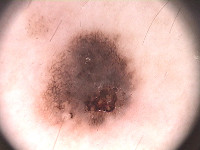</td><td>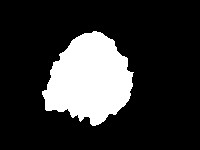</td></tr></table>

2. Разархивируем .rar файл.
3. Обратите внимание, что папка  `PH2 Dataset images` должна лежать там же где и ipynb notebook.

Это фотографии двух типов **поражений кожи:** меланома и родинки.
В данном задании мы не будем заниматься их классификацией, а будем **сегментировать** их.

In [1]:
!gdown 1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql

Downloading...
From (original): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql
From (redirected): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql&confirm=t&uuid=97773171-ddf9-4139-b9af-7cc18006f832
To: /content/PH2Dataset.rar
100% 162M/162M [00:01<00:00, 97.9MB/s]


In [2]:
get_ipython().system_raw("unrar x PH2Dataset.rar")

Стуктура датасета у нас следующая:

    IMD_002/
        IMD002_Dermoscopic_Image/
            IMD002.bmp
        IMD002_lesion/
            IMD002_lesion.bmp
        IMD002_roi/
            ...
    IMD_003/
        ...
        ...

 Здесь `X.bmp` — изображение, которое нужно сегментировать, `X_lesion.bmp` — результат сегментации.

Для загрузки датасета можно использовать skimage: [`skimage.io.imread()`](https://scikit-image.org/docs/dev/api/skimage.io.html)

In [3]:
images = []
lesions = []
from skimage.io import imread
import os
root = 'PH2Dataset'

for root, dirs, files in os.walk(os.path.join(root, 'PH2 Dataset images')):
    if root.endswith('_Dermoscopic_Image'):
        images.append(imread(os.path.join(root, files[0])))
    if root.endswith('_lesion'):
        lesions.append(imread(os.path.join(root, files[0])))

Изображения имеют разные размеры. Давайте изменим их размер на $256\times256 $ пикселей. Для изменения размера изображений можно использовать [`skimage.transform.resize()`](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize).
Эта функция также автоматически нормализует изображения в диапазоне $[0,1]$.


In [4]:
from skimage.transform import resize
size = (256, 256)
X = [resize(x, size, mode='constant', anti_aliasing=True,) for x in images]
Y = [resize(y, size, mode='constant', anti_aliasing=False) > 0.5 for y in lesions]

In [5]:
import numpy as np
X = np.array(X, np.float32)
Y = np.array(Y, np.float32)
print(f'Loaded {len(X)} images')

Loaded 200 images


Чтобы убедиться, что все корректно, мы нарисуем несколько изображений

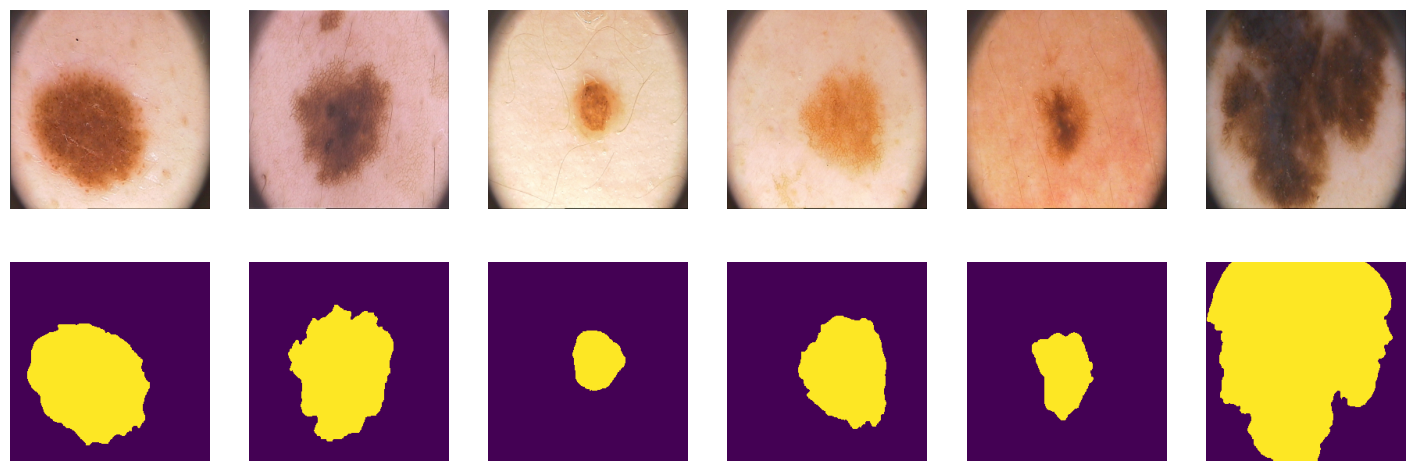

In [6]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.figure(figsize=(18, 6))
for i in range(6):
    plt.subplot(2, 6, i+1)
    plt.axis("off")
    plt.imshow(X[i])

    plt.subplot(2, 6, i+7)
    plt.axis("off")
    plt.imshow(Y[i])
plt.show();

Разделим наши 200 картинок на 100/50/50
 для обучения, валидации и теста соответственно

In [7]:
ix = np.random.choice(len(X), len(X), False)
tr, val, ts = np.split(ix, [100, 150])

In [8]:
print(len(tr), len(val), len(ts))

100 50 50


## PyTorch DataLoader

In [9]:
from torch.utils.data import DataLoader
batch_size = 16
train_dataloader = DataLoader(list(zip(np.rollaxis(X[tr], 3, 1), Y[tr, np.newaxis])),
                     batch_size=batch_size, shuffle=True)
valid_dataloader = DataLoader(list(zip(np.rollaxis(X[val], 3, 1), Y[val, np.newaxis])),
                      batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(list(zip(np.rollaxis(X[ts], 3, 1), Y[ts, np.newaxis])),
                     batch_size=batch_size, shuffle=False)

loaders = {'train': train_dataloader, 'valid': valid_dataloader, 'test': test_dataloader}

In [10]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Шаг 2. Метрика качества модели

## IoU (intersection over union)

В данном разделе предлагается использовать следующую метрику для оценки качества:

$I o U=\frac{\text {target } \cap \text { prediction }}{\text {target } \cup{prediction }}$

Пересечение (A ∩ B) состоит из пикселей, найденных как в маске предсказания, так и в основной маске истины, тогда как объединение (A ∪ B) просто состоит из всех пикселей, найденных либо в маске предсказания, либо в целевой маске.


Что будет являться пересением и объединением в задаче сегментации?

Давайте разберем следующий пример:





<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1rBYFgli48AUUN9idiyq8j3J5DboB93yN" width=1000 height=800/></p>

In [11]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 37.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [12]:
from torchmetrics import JaccardIndex

iou_score = JaccardIndex(threshold=0.5, task="binary", average='none').to(device)

# Задания: Построй свой первый бейзлайн!

Итак, загрузка файлов, код датасета и даталоадера написана за вас. Метрика IoU написана за вас! Вам остается написать лосс, модель и функции обучения и теста модели.

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]

## Шаг 3. Loss функция - BCE [2 балла]

Популярным лоссом для бинарной сегментации является *бинарная кросс-энтропия*, которая задается следующим образом:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

где $y$ это  таргет желаемого результата и $\hat y$ является выходом модели. $\sigma$ - это [*логистическая* функция](https://en.wikipedia.org/wiki/Sigmoid_function), который преобразует действительное число $\mathbb R$ в вероятность $[0,1]$.

Однако эта потеря страдает от проблем численной нестабильности. Самое главное, что $\lim_{x\rightarrow 0^+}\log(x)=-\infty$ приводит к неустойчивости в процессе оптимизации. Рекомендуется посмотреть следующее [упрощение](https://www.tensorflow.org/api_docs/python/tf/nn/sigmoid_cross_entropy_with_logits). Эта функция эквивалентна первой и не так подвержена численной неустойчивости:

$$\mathcal L_{BCE} = \hat y^T \mathbf{1} - y^T \hat y + \mathbf{1}^T \log\left(1+\exp(-\hat y)\right) \space [2]$$

### Вывод численно стабильной формулы BCE лосса [1 балл]



Выведите из формулы [1] формулу [2]:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

$$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right) \space [2]$$

Не забываем, что здесь $\hat y_i$ - это логиты сети, не вероятности и не лейблы.

**Ответ:**

### Реализуйте в коде оба варианта лосса [1 балл]

Реализуйте следующие функции:

*   `bce_true()` - честная прямая реализация лосса с формулой $$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$
*   `bce_loss()` - реализация формулы, которую мы вывели $$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right).$$

И сравните результаты функций с реализацией Pytorch:
*   `bce_torch()`
*   `bce_torch_with_logits()`

In [13]:
import torch.nn.functional as F
import torch.nn as nn
import torch

In [14]:
bce_torch = nn.BCELoss(reduction='sum') # (sigmoid(y_pred), y_real)
bce_torch_with_logits = nn.BCEWithLogitsLoss(reduction='sum')

In [15]:
def bce_loss(y_pred, y_real):
  summa = torch.sum(y_real * torch.log(torch.sigmoid(y_pred)) + (torch.ones_like(y_pred) - y_real) * torch.log(torch.ones_like(y_pred) - torch.sigmoid(y_pred)))
  return - summa

def bce_true(y_pred, y_real):
  return torch.sum(y_pred - y_real * y_pred + torch.log(1 + torch.exp(-y_pred)))

Проверим корректность работы на простом примере

In [16]:
y_pred = torch.randn(3, 2, requires_grad=False)
y_true = torch.rand(3, 2, requires_grad=False)

print(f'BCE loss from scratch bce_loss             = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный                = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch              = {bce_torch(torch.sigmoid(y_pred), y_true)}')
print(f'BCE loss from torch with logits bce_torch  = {bce_torch_with_logits(y_pred, y_true)}')


BCE loss from scratch bce_loss             = 5.5917768478393555
BCE loss честно посчитанный                = 5.591776371002197
BCE loss from torch bce_torch              = 5.5917768478393555
BCE loss from torch with logits bce_torch  = 5.591776371002197


Инструкции `assert` в Python — это булевы выражения, которые проверяют, является ли условие истинным (`True`). Внизу в коде мы проверяем функция `bce_loss()` выдает тот же результат, что и функция из Pytorch или нет. Если равенства не будет, что будет означать, что результаты функций не совпадают, а значит вы неправильно реализовали фукнцию `bce_loss()`, `assert` возвратит ошибку.

Функция `numpy.isclose()` используется для сравнения двух чисел с учётом допустимой погрешности. Она особенно полезна при работе с числами с плавающей точкой, где точное сравнение может быть проблематичным из-за ограничений представления таких чисел в компьютере.

Как она работает?

`numpy.isclose(a, b, rtol=1e-05, atol=1e-08) `принимает два числа (`a` и `b`) и сравнивает их, учитывая относительную и абсолютную погрешность. Если разница между двумя числами меньше заданного порога, функция возвращает `True`, иначе — `False`.

Параметры:

    rtol: Относительная погрешность (по умолчанию 1e-05). Используется для определения разницы относительно большего значения.
    atol: Абсолютная погрешность (по умолчанию 1e-08). Определяет минимальную разницу, которую следует учитывать.

Мы будем использовать `assert` и `numpy.isclose()` для проверки корректности нашего кода.

In [17]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))

Давайте теперь посчитаем на простом примере, но с теми же размерностями, что и в датасете

In [18]:
y_pred = torch.randn((2, 1, 3, 3), requires_grad=False)
y_true = torch.randint(0, 2, (2, 1, 3, 3))

print(f'BCE loss from scratch bce_loss            = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный               = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch             = {bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float))}')
print(f'BCE loss from torch with logits bce_torch = {bce_torch_with_logits(y_pred, y_true.to(torch.float))}')

BCE loss from scratch bce_loss            = 18.804128646850586
BCE loss честно посчитанный               = 18.804126739501953
BCE loss from torch bce_torch             = 18.804128646850586
BCE loss from torch with logits bce_torch = 18.804128646850586


In [19]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))

Давайте посчитаем на реальных логитах и сегментационной маске:

In [20]:
!gdown --folder 1EX0RW1TRQVkLmR1h6miCQqyhYPFyg28M

Retrieving folder contents
Processing file 1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC labels.pt
Processing file 1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I logits.pt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC
To: /content/for_asserts/labels.pt
100% 1.18k/1.18k [00:00<00:00, 4.36MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I
To: /content/for_asserts/logits.pt
100% 1.18k/1.18k [00:00<00:00, 4.87MB/s]
Download completed


In [21]:
path_to_dummy_samples = '/content/for_asserts'
dummpy_sample = {'logits': torch.load(f'{path_to_dummy_samples}/logits.pt'),
                 'labels': torch.load(f'{path_to_dummy_samples}/labels.pt')}
dummpy_sample['labels'] = dummpy_sample['labels'].to(device)
dummpy_sample['logits'] = dummpy_sample['logits'].to(device)

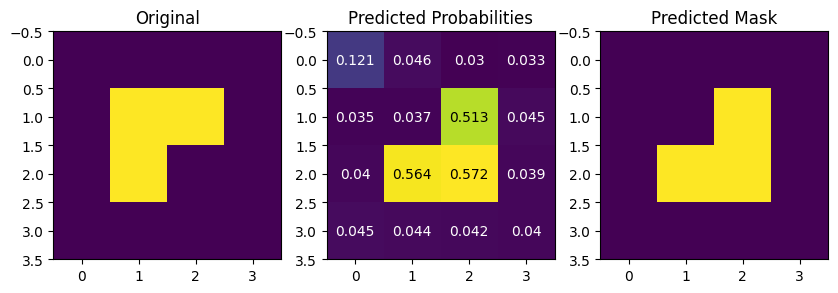

In [22]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize= (10,3*10))

ax1.imshow(dummpy_sample['labels'].squeeze(1)[0].cpu())
ax1.set_title("Original")

ax2.imshow(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu())
for (j,i),label in np.ndenumerate(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu()):
    if label < 0.5:
        color = 'white'
    else:
        color = 'black'
    ax2.text(i,j,round(label,3), color=color, ha='center',va='center')

ax2.set_title("Predicted Probabilities")

ax3.imshow((dummpy_sample['logits'].sigmoid() > 0.5).squeeze(1)[0].cpu())
ax3.set_title("Predicted Mask")
plt.show()

Проверяем на данном примере:

In [23]:
bce_loss_score = bce_loss(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_true_score = bce_true(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_torch_score = bce_torch(torch.sigmoid(dummpy_sample['logits'].cpu()), dummpy_sample['labels'].cpu().float())
bce_torch_with_logits_score = bce_torch_with_logits(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu().float())
assert np.isclose(bce_loss_score, bce_torch_score)
assert np.isclose(bce_loss_score, bce_torch_with_logits_score)
assert np.isclose(bce_true_score, bce_torch_score)
assert np.isclose(bce_true_score, bce_torch_with_logits_score)

## Шаг 4. Модель SegNet [2 балла]

Ваше задание здесь состоит в том, чтобы реализовать SegNet архитектуру.

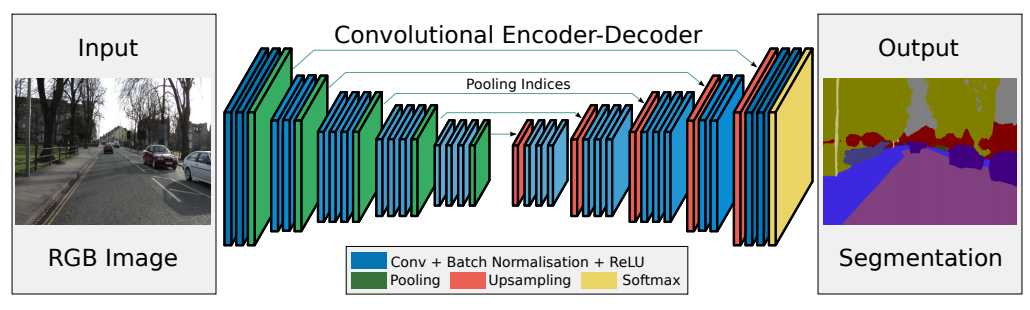

* Badrinarayanan, V., Kendall, A., & Cipolla, R. (2015). [SegNet: A deep convolutional
encoder-decoder architecture for image segmentation](https://arxiv.org/pdf/1511.00561.pdf)

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torch.optim as optim
from time import time

from matplotlib import rcParams
rcParams['figure.figsize'] = (15,4)

Внимательно посмотрите из чего состоит модель и для чего выбраны те или иные блоки. Для этого скачаем и изучим feature extractor VGG-16, который лежит в основе SegNet.

In [25]:
model_vgg16 = models.vgg16(weights = models.VGG16_Weights.IMAGENET1K_V1)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 74.6MB/s]


In [26]:
model_vgg16

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Feature extractor VGG-16 состоит из 5 блоков:
- два блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d
- три блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d

В первом блоке - на входе три канала (по числу каналов в изображениях), которые конволюционный слой преобразует в 64 канала.

Во втором, третьем и четвертом блоках первый конволюционный слой удваивает количество каналов, а последующие конволюционные слои не меняют количество каналов.

В последнем блоке число каналов от слоя к слою не меняется.

Теперь напишем код одного блока энкодера нашей модели SegNet.  

In [27]:
# Параметрами блока будут:
# - количество каналов на входе
# - количество каналов на выходе
# - глубина блока (2 или 3, по количеству конволюционных слоев)
# - kernel_size и padding
#
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth, kernel_size = 3, padding = 1):
        super(EncoderBlock, self).__init__() # инициируем экземляр класса, наследующего от nn.Module
        self.layers = nn.ModuleList() # в self.layers будем добавлять слои блока
        # дальше реализуем то, что на картинке выше обозначено Conv + Batch Normalization + ReLU
        self.layers.append(nn.Conv2d(in_channels = in_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
        self.layers.append(nn.BatchNorm2d(out_channels))
        self.layers.append(nn.ReLU(inplace=True))

        # цикл for помогает использовать один код для блоков как с глубиной 2, так и с глубиной 3
        for i in range(depth-1):
            self.layers.append(nn.Conv2d(in_channels = out_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.maxpooling = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True) #добавляем MaxPool с индексами для последующего Unpooling

    # Обратите внимание: на вход метод forward() получает карту признаков (х),
    # а возвращает карту признаков и индексы для последующего Unpooling
    def forward(self, x):
        k = 0
        for layer in self.layers:
            x = layer(x)
            k += 1
        x, indices = self.maxpooling(x)
        return x, indices



По аналогии напишите код одного блока декодера.

К карте признаков на входе каждого блока примеяется nn.MaxUnpool2d с индексами из симметричного блока энкодера. Затем повторяется связка Conv + Batch Normalization + ReLU. Количество каналов меняется зеркально блокам энкодера:
- в первом блоке декодера количество каналов не меняется
- во 2-4 блоках декодера количество каналов уменьшается в 2 раза после прохождения последнего конволюционного слоя
- на выходе из последнего блока декодера 1 канал

Обратите внимание, что после последней конволюции последнего блока декодера не применяется батч-нормализация и функция активации.

In [28]:
class DecoderBlock(nn.Module):
  def __init__(self, in_channels, out_channels, depth, kernel_size=3, padding=1, last_activation=True):
        super().__init__()
        self.maxunpooling = nn.MaxUnpool2d(kernel_size=2, stride=2)
        self.layers = nn.ModuleList()

        for _ in range(depth - 1):
            self.layers.append(nn.Conv2d(in_channels, in_channels, kernel_size=kernel_size, padding=padding))
            self.layers.append(nn.BatchNorm2d(in_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding))
        if last_activation:
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

  # Обратите внимание: на вход метод forward() получает карту признаков (х),
  # а возвращает карту признаков и индексы для последующего Unpooling
  def forward(self, x, indicies):
      x = self.maxunpooling(x, indicies)
      k = 0
      for layer in self.layers:
          x = layer(x)
          k += 1
      return x


Соединим блоки энкодера и декодера в модель SegNet:

In [29]:
class SegNet(nn.Module):
    def __init__(self, in_channels=3, out_channels = 1, num_features = 64) -> None:
        super(SegNet, self).__init__()

        # Encoder
        self.encoder0 = EncoderBlock(in_channels, num_features, depth=2)
        self.encoder1 = EncoderBlock(num_features, num_features * 2, depth=2)
        num_features = int(num_features * 2)
        self.encoder2 = EncoderBlock(num_features, num_features * 2, depth=3)
        num_features = int(num_features * 2)
        self.encoder3 = EncoderBlock(num_features, num_features * 2, depth=3)
        num_features = int(num_features * 2)

        # Encoder bottleneck - количество каналов на входе и на выходе одинаково
        self.encoder4 = EncoderBlock(num_features, num_features, depth=3)

        # Decoder bottleneck
        self.decoder4 = DecoderBlock(num_features, num_features, depth=3)

        # Decoder
        self.decoder3 = DecoderBlock(num_features, int(num_features/2), depth=3)
        num_features = int(num_features / 2)
        self.decoder2 = DecoderBlock(num_features, int(num_features/2), depth=3)
        num_features = int(num_features / 2)
        self.decoder1 = DecoderBlock(num_features, int(num_features/2), depth=2)
        num_features = int(num_features / 2)
        self.decoder0 = DecoderBlock(num_features, 1, depth=2, last_activation = False)

    def forward(self, x):
        # encoder
        x, indices0 = self.encoder0(x)
        x, indices1 =  self.encoder1(x)
        x, indices2 =  self.encoder2(x)
        x, indices3 =  self.encoder3(x)
        x, indices4 =  self.encoder4(x)

        output = self.decoder4(x, indices4)
        output = self.decoder3(output, indices3)
        output = self.decoder2(output, indices2)
        output = self.decoder1(output, indices1)
        output = self.decoder0(output, indices0)
        return output

## Шаг 5. Тренировка модели [1 балл]

Напишите функции для обучения модели.

In [30]:
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

In [31]:
from IPython.display import clear_output, display
def one_epoch_train(model, optimizer, loss_function, model_metric, train_dataloader):
  model.train()
  losses = []
  model_metric.reset()
  loader_size = 0
  for X_batch, y_batch in train_dataloader:
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    optimizer.zero_grad()
    output = model(X_batch)
    loss = loss_function(output, y_batch)
    loss.backward()

    losses.append(loss.item() * X_batch.size(dim=0))
    loader_size += X_batch.size(dim=0)

    model_metric.update(output, y_batch.to(int))

    optimizer.step()
  epoch_metric = model_metric.compute().item()
  return sum(losses)/loader_size, epoch_metric

def one_epoch_valid(model, loss_function, model_metric, test_loader):
  model.eval()
  losses = []
  model_metric.reset()
  loader_size = 0

  with torch.no_grad():
    for X_batch, y_batch in test_loader:
      X_batch = X_batch.to(device)
      y_batch = y_batch.to(device)

      output = model(X_batch)
      loss = loss_function(output, y_batch)

      losses.append(loss.item() * X_batch.size(dim=0))
      loader_size += X_batch.size(dim=0)

      model_metric.update(output, y_batch.to(int))
    epoch_metric = model_metric.compute().item()
    return sum(losses)/loader_size, epoch_metric

def plot_results(epoch_losses_train, epoch_losses_valid, epoch_target_train, epoch_target_valid, epoch = 0):

  epoch_range = range(1, len(epoch_losses_train) + 1)

  if epoch == 0:
      fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))


      line1, = ax[0].plot([], [], label='Train')
      line2, = ax[0].plot([], [], label='Valid')
      ax[0].legend()

      line3, = ax[1].plot([], [], label='Train')
      line4, = ax[1].plot([], [], label='Valid')
      ax[1].legend()

  line1.set_data(epoch_range, epoch_losses_train)
  line2.set_data(epoch_range, epoch_losses_valid)

  line3.set_data(epoch_range, epoch_target_train)
  line4.set_data(epoch_range, epoch_target_valid)

  for a in ax:
      a.relim()
      a.autoscale_view()

  clear_output(wait=True)
  display(fig)
  plt.close(fig)

In [32]:
import copy
def train(model, optimizer, scheduler, loss_function, model_metric, loaders, epochs = 5, patience = 5):
  epoch_losses_train = []
  epoch_losses_valid = []
  epoch_target_train = []
  epoch_target_valid = []
  best_loss = np.inf
  early_trigger = 0
  for i in range(epochs):
    print(f"Epoch {i+1}")
    train_loss, train_target = one_epoch_train(model, optimizer, loss_function, model_metric, loaders['train'])
    epoch_losses_train.append(float(train_loss))
    epoch_target_train.append(float(train_target))

    valid_loss, valid_target = one_epoch_valid(model, loss_function, model_metric, loaders['valid'])
    epoch_losses_valid.append(float(valid_loss))
    epoch_target_valid.append(float(valid_target))

    if len(epoch_losses_valid) >= 2:
      if valid_loss > epoch_losses_valid[-2]:
        early_trigger += 1
      else:
        early_trigger = 0

    if early_trigger >= patience:
      break

    if best_loss > valid_loss:
      best_model = copy.deepcopy(model.state_dict())
      best_loss = valid_loss

    plot_results(epoch_losses_train, epoch_losses_valid, epoch_target_train, epoch_target_valid)
    scheduler.step(valid_loss)
  return model.load_state_dict(best_model), epoch_target_valid

Обучите модель **SegNet**. В качестве оптимайзера можно взять Adam.

In [33]:
losses_result = {}

In [34]:
model_bce = SegNet()
optimizer_bce = torch.optim.Adam(model_bce.parameters(), lr = 3e-4)
scheduler_bce = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_bce, factor = 0.5, patience=5, threshold = 1e-6)

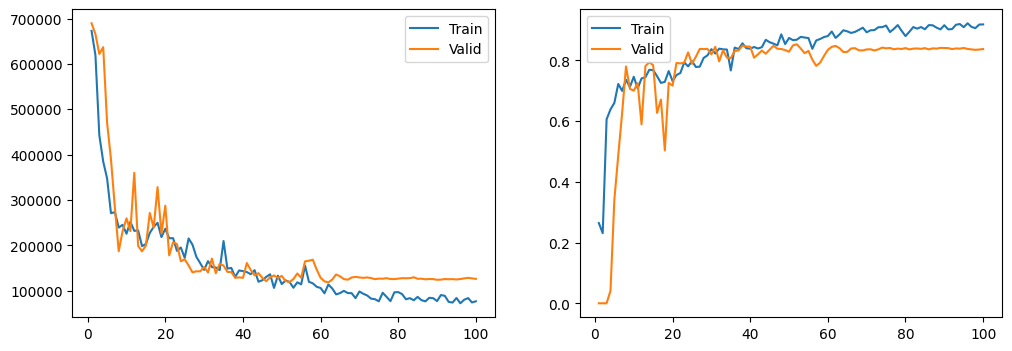

In [35]:
# TODO
_ , target_with_bce = train(model_bce.to(device), optimizer_bce, scheduler_bce, bce_torch_with_logits, iou_score, loaders, epochs = 100, patience = 20)

In [36]:
losses = {'bce': target_with_bce}

## Шаг 6. Инференс [1 балл]

После обучения модели напишите функцию теста, воспользуйтесь лучшим чекпоинтом и протестируйте работу модели на тестовой выборке.

In [37]:
# def test(model, loss_function, model_metric, test_loader):


In [38]:
one_epoch_valid(model_bce, bce_true, iou_score, loaders['test'])

(161176.01134765625, 0.8254250884056091)

# Задания: Мир других лоссов!

## Пробуем другие функции потерь [2 балла]

В данном разделе вам потребуется имплементировать две функции потерь: DICE и Focal loss.


### Dice Loss

**1. Dice coefficient:** Учитывая две маски $X$ и $Y$, общая метрика для измерения расстояния между этими двумя масками задается следующим образом:

$$D(X,Y)=\frac{2|X\cap Y|}{|X|+|Y|}$$

В терминах матрицы ошибок она будет считаться следующим образом:

$$D(X,Y) = \frac{2TP}{2TP + FP + FN}$$

Эта функция не является дифференцируемой, но это необходимое свойство для градиентного спуска. В данном случае мы можем приблизить его с помощью:

$$\mathcal L_D(X,Y) = 1- D(X, Y)$$

**Hints** (!):

1. Не забудьте подумать о численной нестабильности, возникающей в математической формуле при ситуации, когда $\frac{0}{0}$, т.е. вам нужно добавить очень маленькое число, например $\epsilon = 1e^{-8}$, в обе части дроби при подсчете $D(X,Y)$:

$$D(X,Y) = \frac{2TP + ϵ}{2TP + FP + FN + ϵ}$$

2. Dice метрика(!), не лосс, считается похожим образом как IoU:

    2.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    2.2. Фиксируем порог, например threshold=0.5, и всему что ниже порога ставим значение 0, всему что выше 1. Получаем предсказанную маску из 0 и 1.

    2.3. Считаем TP, FP, FN

    2.4. Считаем DICE метрику по формуле

Вы можете прописать для себя функцию `dice_score()` и сравнить с результатами работы функции из библиотеки `torchmetrics`.

3. Но с метрикой есть проблема, что она не дифференцируема, и если вы захотите просто взять и прописать `dice_loss` = 1 - `dice_score`, Pytorch поругается на вас и скажет, что это недифференцируемая метрика. Чтобы посчитать dice_loss делаем следующие шаги:

    3.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    3.2. Здесь нам уже не нужно фиксировать порог, мы просто работаем с вероятностями. Значения вероятностей дифференцируемы и через них будут протекать градиенты.

    3.3. Считаем TP, FP, FN также как и в Dice метрике, только вместо маски, подаем вероятности.

    3.4. Считаем DICE метрику по формуле

    3.5. Считаем лосс как Loss = 1 - DICE

Итак, давайте сначала пропишем dice_score.

In [39]:
def dice_score(logits: torch.Tensor, labels: torch.Tensor, threshold: float = 0.5):
    '''
    Это именно метрика, не лосс.
    '''
    sigma_logits = (torch.sigmoid(logits) > threshold).to(int)

    tp = abs(labels * sigma_logits).float().sum().item()
    fp = ((sigma_logits) & (labels == 0)).float().sum().item()
    fn = ((labels) & (sigma_logits ==0)).float().sum().item()

    metric = (2 * tp + 1e-8)/(2 * tp + fp + fn + 1e-8)

    return metric

Проверим на корректность функцию dice_score:

In [40]:
from torchmetrics.segmentation import DiceScore

dice = DiceScore(num_classes=1, average='micro').to(device)
dice((dummpy_sample['logits'].sigmoid()> 0.5).to(int), dummpy_sample['labels'].to(int))

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: DiceScore metric currently defaults to `average=micro`, but will change to`average=macro` in the v1.9 release. If you've explicitly set this parameter, you can ignore this warning.
  warnings.warn(*args, **kwargs)


tensor(0.6667, device='cuda:0')

In [41]:
'''
если вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():

from torchmetrics.classification import Dice

dice = Dice(average='micro').to(device)

'''

"\nесли вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():\n\nfrom torchmetrics.classification import Dice\n\ndice = Dice(average='micro').to(device)\n\n"

In [42]:
# У меня получилось добиться одинакого результата только при условии, что я в dice передаю в эту метрику
assert dice((dummpy_sample['logits'].sigmoid()> 0.5).to(int), dummpy_sample['labels'].to(int)) == dice_score(dummpy_sample['logits'], dummpy_sample['labels'].to(int))

Давайте теперь пропишем лосс и воспользуемся библиотекой `segmentation-models-pytorch`, чтобы убедиться в корректности нашей функции.

In [43]:
def dice_loss(logits: torch.Tensor, labels: torch.Tensor):

    '''
    Это лосс.
    '''

    sigma_logits = torch.sigmoid(logits)

    tp = (labels * sigma_logits).sum()
    der = labels.sum() + sigma_logits.sum()

    loss = (2 * tp + 1e-8)/(der + 1e-8)

    return 1 - loss

Проверка на корректность:

In [44]:
# проверьте, что у вас установлена библиотека
!pip install segmentation-models-pytorch

In [45]:
from segmentation_models_pytorch.losses import DiceLoss
dice_loss_torch = DiceLoss(mode='binary')
dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756, device='cuda:0')

In [46]:
assert dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'].to(int)) == dice_loss(dummpy_sample['logits'], dummpy_sample['labels'])

In [47]:
model_dice = SegNet()
optimizer = torch.optim.Adam(model_dice.parameters(), lr = 3e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor = 0.5, patience=5, threshold = 1e-6)

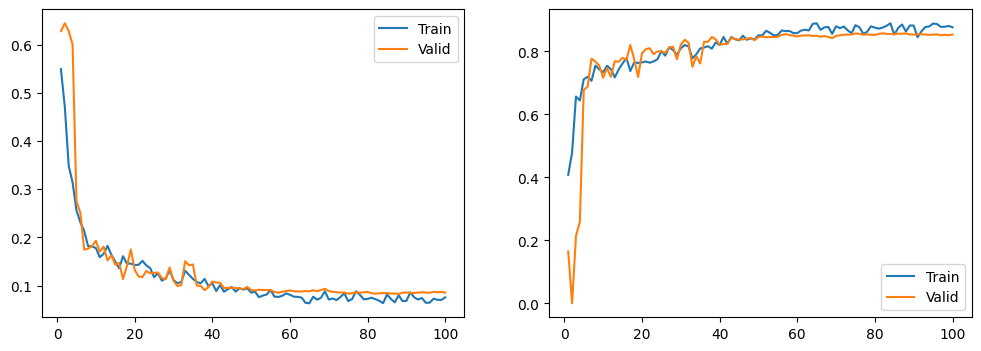

In [48]:
_ , target_with_dice = train(model_dice.to(device), optimizer, scheduler, dice_loss_torch, iou_score, loaders, epochs = 100, patience = 5)

In [49]:
losses['dice'] = target_with_dice

In [85]:
one_epoch_valid(model_dice, dice_loss_torch, iou_score, loaders['test'])

(0.11015549659729004, 0.8052672147750854)

### Focal Loss

[**2. Focal loss:**](https://arxiv.org/pdf/1708.02002.pdf)

Окей, мы уже с вами умеем делать BCE loss:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Проблема с этой потерей заключается в том, что она имеет тенденцию приносить пользу классу **большинства** (фоновому) по отношению к классу **меньшинства** ( переднему). Поэтому обычно применяются весовые коэффициенты к каждому классу:

$$\mathcal L_{wBCE}(y, \hat y) = -\sum_i \alpha_i\left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Традиционно вес $\alpha_i$ определяется как обратная частота класса этого пикселя $i$, так что наблюдения миноритарного класса весят больше по отношению к классу большинства.


Из оригинальной статьи по [Focal Loss](https://arxiv.org/pdf/1708.02002.pdf):

$$p_t = \sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)$$

$$\mathcal L_{focal}(y, \hat y) = (1 - p_t)^{\gamma} \mathcal L_{BCE}(y_i, \hat y_i).$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - p_t)^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - (\sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)))^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

In [50]:
def focal_loss(y_real, y_pred, eps = 1e-8, gamma = 2):

    sigma_pred = torch.clamp(torch.sigmoid(y_pred), min=eps, max=1.0 - eps)
    anti_sigma_pred = 1 - sigma_pred
    anti_real = 1 - y_real

    first_part = (1 - (sigma_pred * y_real + (anti_sigma_pred) * anti_real))**gamma
    second_part = y_pred - y_real * y_pred + torch.log(1 + torch.exp(-y_pred))
    loss = (first_part * second_part).sum()

    return loss

Проверка корректности функции:

In [51]:
from torchvision.ops import sigmoid_focal_loss
sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum')

tensor(3.6161, device='cuda:0')

In [52]:
assert np.isclose(sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum').cpu().item(), focal_loss(dummpy_sample['labels'], dummpy_sample['logits'], gamma=2.0).cpu().item())

In [53]:
model_focal = SegNet()
optimizer = torch.optim.Adam(model_focal.parameters(), lr = 3e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor = 0.5, patience=5, threshold = 1e-6)

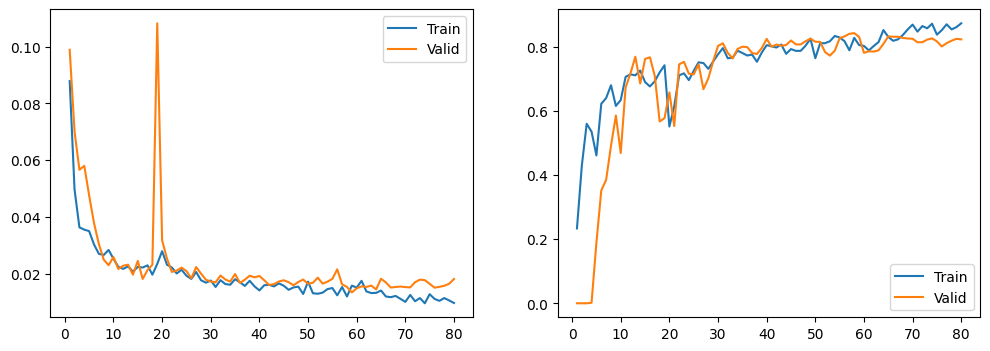

Epoch 81


In [54]:
_ , target_with_focal = train(model_focal.to(device), optimizer, scheduler, lambda outputs, targets: sigmoid_focal_loss(outputs, targets, alpha=0.25, gamma=2.0, reduction='mean'), iou_score, loaders, epochs = 100, patience = 5)

In [55]:
losses['focal'] = target_with_focal

In [86]:
one_epoch_valid(model_focal, lambda outputs, targets: sigmoid_focal_loss(outputs, targets, alpha=0.25, gamma=2.0, reduction='mean'), iou_score, loaders['test'])

(0.018287332765758037, 0.7814509868621826)

## [BONUS] Мир сегментационных лоссов [5 баллов]

В данном блоке предлагаем вам написать одну функцию потерь самостоятельно. Для этого необходимо прочитать статью и имплементировать ее, и провести численное сравнение с предыдущими функциями.
 **ВАЖНО:** за имплементацию одного лосса выдается только один балл. Чтобы получить все 5 баллов, будет необходимо имплементировать все 5 лоссов.

* [Physiological Inspired Deep Neural Networks for Emotion Recognition](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8472816&tag=1)". IEEE Access, 6, 53930-53943.

* [Boundary loss for highly unbalanced segmentation](https://arxiv.org/abs/1812.07032)

* [Tversky loss function for image segmentation using 3D fully convolutional deep networks](https://arxiv.org/abs/1706.05721)

* [Correlation Maximized Structural Similarity Loss for Semantic Segmentation](https://arxiv.org/abs/1910.08711)

* [Topology-Preserving Deep Image Segmentation](https://papers.nips.cc/paper/8803-topology-preserving-deep-image-segmentation)

## Обучите SegNet на новых лоссах

**Задание**: обучите SegNet на новых лоссах и сравните все три лосса:
*   При каком лоссе модель сходится быстрее?
*   При каком лоссе модель выдает наилучшую метрику?

В обоих случаях dice лосс показ лучший результат. Он показал максимальную метрику на валидационной выборке и при этом вышел на этот результат быстрее всего. Dice крут. Хотя на тестовой выборке чуть лучше себя проявила модель с bce лоссом


In [69]:
#Дополним датасет по focal последним значением, так как он закончил учиться раньше
rep = 100 - len(losses['focal'])

losses['focal'].extend([losses['focal'][-1]] * rep)

import pandas as pd
target_val = pd.DataFrame().from_dict(losses)

m_target_val = target_val.reset_index().melt(id_vars = 'index')


{'bce': [0.0,
  0.0,
  0.0,
  0.04092366248369217,
  0.34178730845451355,
  0.48641854524612427,
  0.6260407567024231,
  0.7796455025672913,
  0.7060892581939697,
  0.700035035610199,
  0.7247104048728943,
  0.5891441702842712,
  0.7810159921646118,
  0.7934988141059875,
  0.783922553062439,
  0.6266785264015198,
  0.6707963347434998,
  0.503235936164856,
  0.7259452939033508,
  0.7164804339408875,
  0.7911756038665771,
  0.7898107171058655,
  0.7922050356864929,
  0.826083242893219,
  0.7884544134140015,
  0.8115782737731934,
  0.8374916315078735,
  0.8370655179023743,
  0.8374651670455933,
  0.819515585899353,
  0.844260036945343,
  0.7965320348739624,
  0.8332388997077942,
  0.8087604641914368,
  0.807388186454773,
  0.8306856155395508,
  0.8323489427566528,
  0.8482330441474915,
  0.845539391040802,
  0.844889760017395,
  0.8086711168289185,
  0.8196656107902527,
  0.8319776654243469,
  0.8215706944465637,
  0.8352080583572388,
  0.8477873802185059,
  0.8381675481796265,
  0.837250

<Axes: xlabel='index', ylabel='value'>

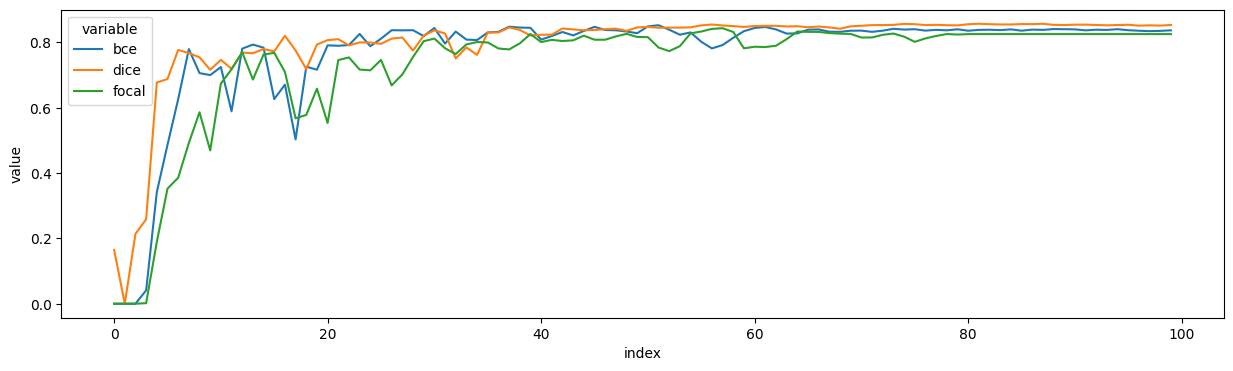

In [84]:
import seaborn as sns
sns.lineplot(data = m_target_val, x = 'index', y = 'value', hue = 'variable')

# Задание: Новая модель!

## Модель U-Net [2 балла]

[**U-Net**](https://arxiv.org/abs/1505.04597) — это архитектура нейронной сети, которая получает изображение и выводит его. Первоначально он был задуман для семантической сегментации (как мы ее будем использовать), но он настолько успешен, что с тех пор используется в других контекстах. Получая на вход медицинское изображение, он выведет изображение в оттенках серого, где интенсивность каждого пикселя зависит от вероятности того, что этот пиксель принадлежит интересующей нас области.

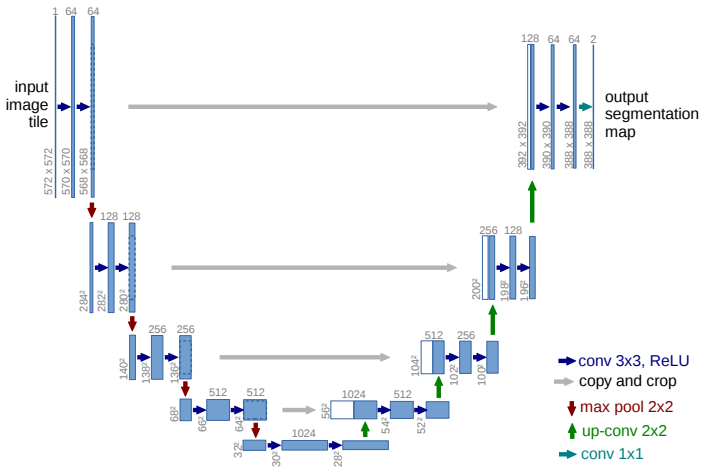

У нас в архитектуре все так же существует энкодер и декодер, как в **SegNet**, но отличительной особеностью данной модели являются *skip-conenctions*, соединяющие части декодера и энкодера. То есть для того чтобы передать на вход декодера тензор, мы конкатенируем симметричный выход с энкодера и выход предыдущего слоя декодера.

* Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "[U-Net: Convolutional networks for biomedical image segmentation.](https://arxiv.org/pdf/1505.04597.pdf)" International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

В оригинальной статье авторы не использовали padding внутри модели (это видно по тому, что размеры карты признаков уменьшаются на 2 каждый раз при движении от слоя к слою). При этом размеры входных изображений авторы единоразово увеличили при помощи mirror padding.

В этом домашнем задании вы можете применить альтернативный подход - сохранять размеры карт признаков при помощью padding = 1 во внутренних слоях.  

In [87]:
import torch.nn.functional as F
import torch.nn as nn

Для реализации UNet вы можете написать классы блоков энкодера и декодера отдельно, как мы сделали при реализации SegNet.

In [98]:
class UNet(nn.Module):
    def __init__(self, n_class=1):
        super().__init__()

        self.encoder0 = EncoderBlock(3, 64, depth=2)
        self.encoder1 = EncoderBlock(64, 128, depth=2)
        self.encoder2 = EncoderBlock(128, 256, depth=2)
        self.encoder3 = EncoderBlock(256, 512, depth=2)
        self.encoder4 = EncoderBlock(512, 1024, depth=2)

        self.encoder5 = EncoderBlock(1024, 1024, depth=1)

        self.decoder5 = DecoderBlock(1024, 1024, depth=1)

        self.decoder4 = DecoderBlock(1024, 512, depth=2)
        self.decoder3 = DecoderBlock(512, 256, depth=2)
        self.decoder2 = DecoderBlock(256, 128, depth=2)
        self.decoder1 = DecoderBlock(128, 64, depth=2)
        self.decoder0 = DecoderBlock(64, 1, depth=2)



    def forward(self, x):
        x1, indicies0 = self.encoder0(x)
        x2, indicies1 = self.encoder1(x1)
        x3, indicies2 = self.encoder2(x2)
        x4, indicies3 = self.encoder3(x3)
        x5, indicies4 = self.encoder4(x4)

        x6, indicies5 = self.encoder5(x5)

        x7 = self.decoder5(x6, indicies5)

        x8 = self.decoder4(x7 + x5, indicies4)
        x9 = self.decoder3(x8 + x4, indicies3)
        x10 = self.decoder2(x9 + x3, indicies2)
        x11 = self.decoder1(x10 + x2, indicies1)
        x12 = self.decoder0(x11 + x1, indicies0)


        return x12

In [99]:
model_bce_unet = UNet().to(device)
optimizer_bce_unet = torch.optim.Adam(model_bce_unet.parameters(), lr = 3e-4)
scheduler_bce_unet = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_bce_unet, factor = 0.5, patience=5, threshold = 1e-6)

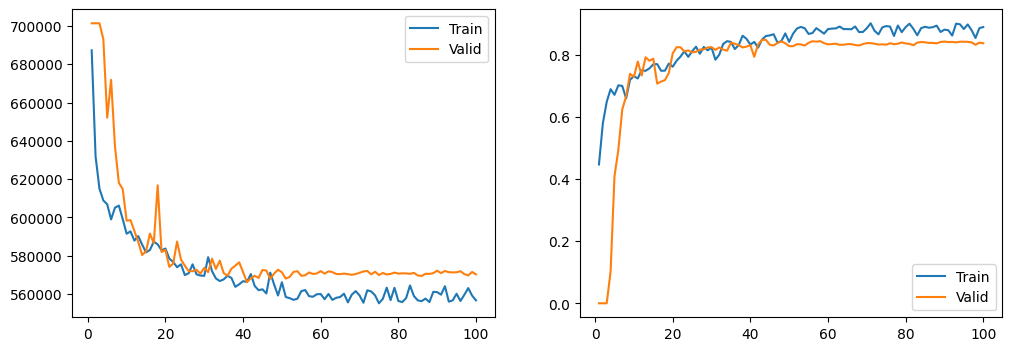

In [100]:
# TODO
_ , target_with_bce = train(model_bce_unet.to(device), optimizer_bce_unet, scheduler_bce_unet, bce_torch_with_logits, iou_score, loaders, epochs = 100, patience = 20)

In [102]:
unet_losses = {'bce': target_with_bce}

In [101]:
model_dice_unet = UNet().to(device)
optimizer_dice_unet = torch.optim.Adam(model_dice_unet.parameters(), lr = 3e-4)
scheduler_dice_unet = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_dice_unet, factor = 0.5, patience=5, threshold = 1e-6)

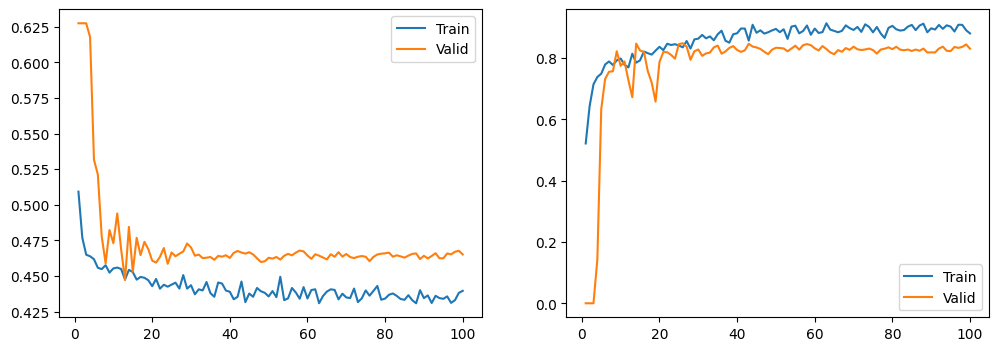

In [103]:
# TODO
_ , target_with_dice_unet = train(model_dice_unet.to(device), optimizer_dice_unet, scheduler_dice_unet, dice_loss_torch, iou_score, loaders, epochs = 100, patience = 20)

In [104]:
unet_losses['dice'] = target_with_dice_unet

In [105]:
model_focal_unet = UNet().to(device)
optimizer_focal_unet = torch.optim.Adam(model_focal_unet.parameters(), lr = 3e-4)
scheduler_focal_unet = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_focal_unet, factor = 0.5, patience=5, threshold = 1e-6)

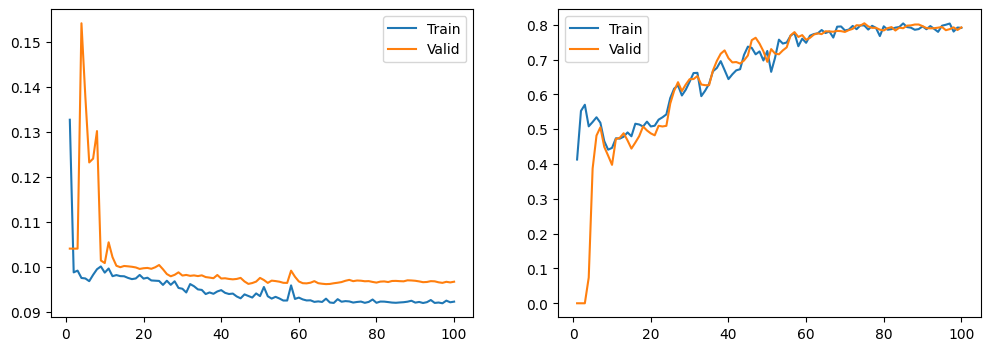

In [106]:
# TODO
_ , target_with_focal_unet = train(model_focal_unet.to(device), optimizer_focal_unet, scheduler_focal_unet, lambda outputs, targets: sigmoid_focal_loss(outputs, targets, alpha=0.25, gamma=2.0, reduction='mean'), iou_score, loaders, epochs = 100, patience = 20)

In [107]:
unet_losses['focal'] = target_with_focal_unet

In [108]:
import pandas as pd
target_val_unet = pd.DataFrame().from_dict(unet_losses)

m_target_val_unet = target_val_unet.reset_index().melt(id_vars = 'index')

<Axes: xlabel='index', ylabel='value'>

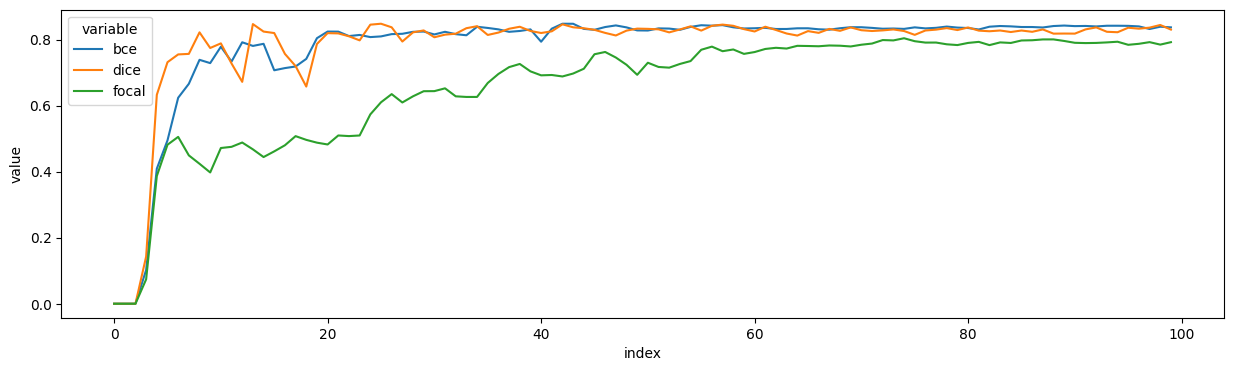

In [110]:
sns.lineplot(data = m_target_val_unet, x = 'index', y = 'value', hue = 'variable')

In [112]:
m_target_val_unet['model'] = 'unet'
m_target_val['model'] = 'segnet'

<Axes: xlabel='index', ylabel='value'>

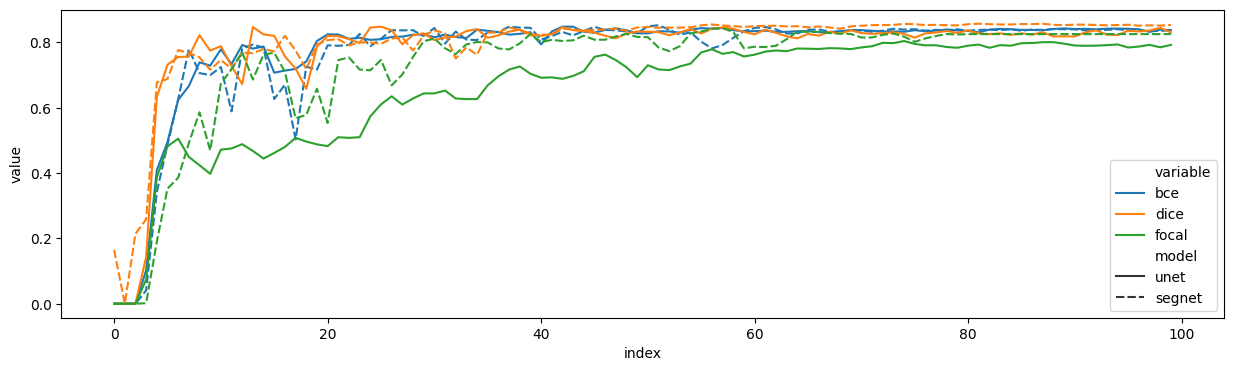

In [114]:
sns.lineplot(data = pd.concat([m_target_val_unet, m_target_val], axis = 0), x = 'index', y = 'value', hue = 'variable', style = 'model')

## Обучите UNet

Задание: обучите UNet на всех трех лоссах: BCE, Dice, Focal и сравните результаты с SegNet:
*   Какая модель дает лучшие значения по метрике?
*   Какая модель дает лучшие значения по лоссам?
*   Какая модель обучается быстрее?
*   Сравните визуально результаты SegNet и UNet.

Напишите развернутый ответ на вопросы.

